# Off-lineage leakage after held-out prediction

This notebook evaluates whether strict leave-one-stage-out (LOSO) predictions from observed E7.5 cells enter developmentally incompatible compartments at the omitted E8.0 or E8.5 stage.

Each predicted RNA endpoint receives a **soft five-nearest-neighbour annotation** from observed cells at the held-out stage. For each E7.5 source cell type, off-lineage leakage is the mean fraction of its five neighbours assigned to an incompatible lineage. Balanced predictions use uniform particle weights; unbalanced predictions use the native predicted mass, normalized within each source cell type.

## Required LOSO results

Run the four strict LOSO models first. Each output folder must contain `heldout_prediction.npz`:

```bash
python -m examples.gastrulation.train_balanced_loso --held-out-stage E8.0 --output outputs/gastrulation-balanced-loo-e8.0
python -m examples.gastrulation.train_unbalanced_loso --held-out-stage E8.0 --output outputs/gastrulation-unbalanced-loo-e8.0
python -m examples.gastrulation.train_balanced_loso --held-out-stage E8.5 --output outputs/gastrulation-balanced-loo-e8.5
python -m examples.gastrulation.train_unbalanced_loso --held-out-stage E8.5 --output outputs/gastrulation-unbalanced-loo-e8.5
```

The calculation uses RNA PCA50 rather than UMAP. The stored predictions and observed embeddings are both in the original PCA scale. Dividing both by the same global scalar would leave all Euclidean nearest-neighbour assignments unchanged.

In [1]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import NearestNeighbors

project_dir = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "pyproject.toml").exists() and (p / "src/coati").is_dir()), None)
if project_dir is None:
    raise FileNotFoundError("Run this notebook inside a COATI checkout.")

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 10})

Matplotlib is building the font cache; this may take a moment.


In [2]:
data_path = project_dir / "examples/gastrulation/data/gastrulation_embeddings.h5ad"
cells = ad.read_h5ad(data_path)

run_specs = [
    ("E8.0", 1.0, "Balanced", project_dir / "outputs/gastrulation-balanced-loo-e8.0"),
    ("E8.0", 1.0, "Unbalanced", project_dir / "outputs/gastrulation-unbalanced-loo-e8.0"),
    ("E8.5", 2.0, "Balanced", project_dir / "outputs/gastrulation-balanced-loo-e8.5"),
    ("E8.5", 2.0, "Unbalanced", project_dir / "outputs/gastrulation-unbalanced-loo-e8.5"),
]

runs = {}
for stage, target_time, model, directory in run_specs:
    prediction_path = directory / "heldout_prediction.npz"
    if not prediction_path.exists():
        raise FileNotFoundError(f"Missing {prediction_path}")
    with np.load(prediction_path, allow_pickle=False) as archive:
        runs[(stage, model)] = {key: np.asarray(archive[key]) for key in archive.files}

[(stage, model, runs[(stage, model)]["primary"].shape)
 for stage, _, model, _ in run_specs]

[('E8.0', 'Balanced', (9018, 50)),
 ('E8.0', 'Unbalanced', (9018, 50)),
 ('E8.5', 'Balanced', (9018, 50)),
 ('E8.5', 'Unbalanced', (9018, 50))]

## Conservative lineage definitions

Only E7.5 source types with more than 200 cells and evidence class A or B are included. Class M marks multipotent or transitional states for which a single-germ-layer leakage score is not identifiable at this resolution. `Unannotated` and progenitor/primitive-streak target labels are treated as ambiguous rather than errors.

In [3]:
CELLTYPE_ALIASES = {
    "Definitive endoderm": "Def. endoderm",
    "Caudal mesoderm": "Caudal Mesoderm",
    "Unknown": "Unannotated",
    "unknown": "Unannotated",
    "nan": "Unannotated",
}

CELLTYPE_GROUPS = {
    "Progenitor / primitive streak": {
        "Epiblast", "Primitive Streak", "Anterior Primitive Streak",
        "Caudal epiblast", "PGC",
    },
    "Neural / ectoderm": {
        "Rostral neurectoderm", "Caudal neurectoderm",
        "Forebrain/Midbrain/Hindbrain", "Spinal cord", "Neural crest",
        "Surface ectoderm",
    },
    "Axial / paraxial mesoderm": {
        "NMP", "Nascent mesoderm", "Mixed mesoderm", "Caudal Mesoderm",
        "Paraxial mesoderm", "Somitic mesoderm", "Notochord",
    },
    "Other mesoderm": {
        "Pharyngeal mesoderm", "Intermediate mesoderm", "Cardiomyocytes",
        "Mesenchyme", "Allantois",
    },
    "Haemato-endothelial": {
        "Haematoendothelial progenitors", "Endothelium",
        "Blood progenitors 1", "Blood progenitors 2",
        "Erythroid1", "Erythroid2", "Erythroid3",
    },
    "Endoderm": {"Def. endoderm", "Gut"},
    "Other / missing": {"Unannotated"},
}

SOURCE_CLASS = {
    "Rostral neurectoderm": "A", "Nascent mesoderm": "B",
    "Mesenchyme": "B", "Epiblast": "M", "Surface ectoderm": "A",
    "Caudal epiblast": "M", "Haematoendothelial progenitors": "A",
    "Pharyngeal mesoderm": "A", "Gut": "A", "Primitive Streak": "M",
    "Somitic mesoderm": "A", "Def. endoderm": "A",
    "Paraxial mesoderm": "A", "Mixed mesoderm": "B",
}

ALL_TARGETS = set().union(*CELLTYPE_GROUPS.values())
AMBIGUOUS_TARGETS = CELLTYPE_GROUPS["Progenitor / primitive streak"] | {"NMP", "Unannotated"}
ECTODERM_TARGETS = CELLTYPE_GROUPS["Neural / ectoderm"]
MESODERM_TARGETS = (
    CELLTYPE_GROUPS["Axial / paraxial mesoderm"]
    | CELLTYPE_GROUPS["Other mesoderm"]
    | CELLTYPE_GROUPS["Haemato-endothelial"]
) - {"NMP"}
ENDODERM_TARGETS = CELLTYPE_GROUPS["Endoderm"]

def canonical_celltype(value):
    text = "Unannotated" if pd.isna(value) else str(value)
    return CELLTYPE_ALIASES.get(text, text)

def lineage_sets(source):
    if source in ECTODERM_TARGETS:
        compatible = set(ECTODERM_TARGETS)
    elif source in MESODERM_TARGETS:
        compatible = set(MESODERM_TARGETS)
    elif source in ENDODERM_TARGETS:
        compatible = set(ENDODERM_TARGETS)
    else:
        raise KeyError(f"No conservative lineage rule for {source}")
    ambiguous = set(AMBIGUOUS_TARGETS)
    incompatible = ALL_TARGETS - compatible - ambiguous
    return compatible, ambiguous, incompatible

def normalized_weights(log_mass, native_mass):
    if not native_mass:
        return np.full(len(log_mass), 1.0 / len(log_mass))
    values = np.asarray(log_mass, dtype=float).reshape(-1)
    weights = np.exp(values - values.max())
    return weights / weights.sum()

## Five-neighbour off-lineage leakage

For each held-out stage, the neighbour index is fitted only on observed cells from that stage. Within a source cell type, each particle contributes the fraction of its five neighbours that falls into the incompatible target set.

In [4]:
times = cells.obs["time"].to_numpy(dtype=float)
labels = np.asarray([canonical_celltype(value) for value in cells.obs["celltype"]], dtype=str)
source_mask = np.isclose(times, 0.0)
source_labels = labels[source_mask]
source_counts = pd.Series(source_labels).value_counts()
source_order = [
    source for source in source_counts[source_counts > 200].index
    if source != "Unannotated" and SOURCE_CLASS.get(source) in {"A", "B"}
]

rows = []
destination_rows = []
for stage, target_time, model, _ in run_specs:
    target_mask = np.isclose(times, target_time)
    reference = np.asarray(cells.obsm["X_pca"][target_mask], dtype=np.float32)
    target_labels = labels[target_mask]
    prediction = np.asarray(runs[(stage, model)]["primary"], dtype=np.float32)
    native_mass = "log_weights" in runs[(stage, model)]
    log_mass = (np.asarray(runs[(stage, model)]["log_weights"], dtype=float).reshape(-1)
                if native_mass else np.zeros(len(prediction)))

    if len(prediction) != len(source_labels):
        raise ValueError(f"{stage}, {model}: prediction/source identity mismatch")
    knn = NearestNeighbors(n_neighbors=5, algorithm="brute", metric="euclidean", n_jobs=-1)
    assignments = target_labels[knn.fit(reference).kneighbors(prediction, return_distance=False)]

    for source in source_order:
        mask = source_labels == source
        weights = normalized_weights(log_mass[mask], native_mass)
        local = assignments[mask]
        compatible, ambiguous, incompatible = lineage_sets(source)
        masses = {
            "on_lineage_mass": np.sum(weights * np.mean(np.isin(local, list(compatible)), axis=1)),
            "ambiguous_mass": np.sum(weights * np.mean(np.isin(local, list(ambiguous)), axis=1)),
            "off_lineage_mass": np.sum(weights * np.mean(np.isin(local, list(incompatible)), axis=1)),
        }
        rows.append({
            "stage": stage, "model": model, "source_celltype": source,
            "source_n": int(source_counts[source]),
            "weighting": "native mass" if native_mass else "uniform",
            **masses,
        })
        for target in np.unique(target_labels):
            destination_rows.append({
                "stage": stage, "model": model, "source_celltype": source,
                "target_celltype": target,
                "mass": np.sum(weights[:, None] * (local == target)) / 5,
            })

off_lineage = pd.DataFrame(rows)
destination_mass = pd.DataFrame(destination_rows)
partition = off_lineage[["on_lineage_mass", "ambiguous_mass", "off_lineage_mass"]].sum(axis=1)
assert np.allclose(partition, 1.0)
assert len(off_lineage) == 4 * len(source_order)

summary = (
    off_lineage.groupby(["stage", "model"], sort=False)
    .apply(lambda frame: pd.Series({
        "source_types": len(frame),
        "source_cells": frame["source_n"].sum(),
        "weighted_off_lineage_mass": np.average(
            frame["off_lineage_mass"], weights=frame["source_n"]
        ),
    }), include_groups=False)
    .reset_index()
)
display(summary.style.format({"weighted_off_lineage_mass": "{:.4f}"}))

,stage,model,source_types,source_cells,weighted_off_lineage_mass
0,E8.0,Balanced,11.000000,6029.000000,0.1116
1,E8.0,Unbalanced,11.000000,6029.000000,0.0339
2,E8.5,Balanced,11.000000,6029.000000,0.0578
3,E8.5,Unbalanced,11.000000,6029.000000,0.0421


## Source-resolved results

In [5]:
source_table = off_lineage.pivot(
    index="source_celltype", columns=["stage", "model"], values="off_lineage_mass"
).reindex(source_order)
display(source_table.style.format("{:.3f}"))

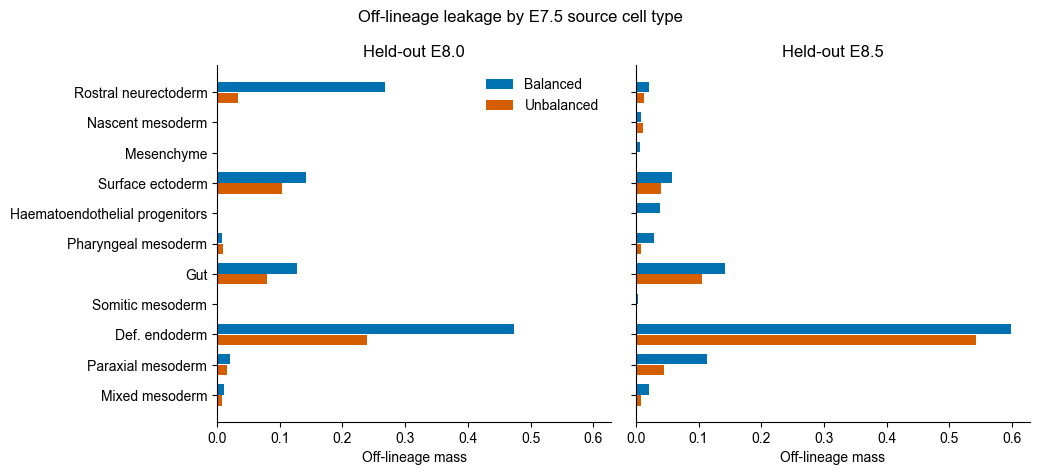

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), sharex=True)
colors = {"Balanced": "#0072B2", "Unbalanced": "#D55E00"}
for ax, stage in zip(axes, ("E8.0", "E8.5")):
    local = off_lineage[off_lineage["stage"] == stage]
    y = np.arange(len(source_order))
    for offset, model in ((-0.18, "Balanced"), (0.18, "Unbalanced")):
        values = local.set_index(["source_celltype", "model"])["off_lineage_mass"]
        ax.barh(y + offset, [values[(source, model)] for source in source_order],
                height=0.34, color=colors[model], label=model)
    ax.set_title(f"Held-out {stage}")
    ax.set_xlabel("Off-lineage mass")
    ax.set_yticks(y, source_order if ax is axes[0] else [])
    ax.invert_yaxis()
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle("Off-lineage leakage by E7.5 source cell type")
fig.tight_layout()

`summary` is the cell-number-weighted result across the included source types. `off_lineage` retains the full source-resolved calculation, while `destination_mass` can be used to inspect which held-out target annotations contribute to a particular leakage value.

This readout measures cross-lineage endpoint assignment, not total population-size accuracy. Native unbalanced mass is normalized within each source cell type before aggregation.